# Exhaled Breathomics for Asthma Classification Using Nested Cross-Validated Logistic Regression

Asthma is a chronic inflammatory airway disease characterized by variable respiratory symptoms, including dyspnea, wheezing, and cough. These symptoms often overlap with other chronic respiratory diseases, such as COPD and bronchiectasis, making diagnosis challenging. A definitive diagnosis requires evidence of variable expiratory airflow limitation, commonly assessed through spirometry. However, spirometry requires patient cooperation and adequate respiratory effort, which may be difficult for young children, frail older adults, and patients unable to perform the test reliably.

This project explores exhaled breathomics as a potential non-invasive approach to support asthma diagnosis. Using A Clinical Breathomics Dataset (Kuo et al., 2024), volatile organic compound (VOC) profiles from patients with asthma, COPD, and bronchiectasis will be analyzed. Machine learning algorithms will be developed and compared to distinguish asthma from other chronic respiratory diseases.

The objective is to identify potential breathomic biomarkers associated with asthma and evaluate their diagnostic potential using machine learning. Further research and clinical validation are needed to establish exhaled breathomics as a potential diagnostic tool for asthma.

## Import Packages and Load Dataset

### Import packages

In [1]:
from pathlib import Path

import pandas as pd 
import numpy as np 

import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, \
    cross_validate, cross_val_predict

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, \
confusion_matrix, ConfusionMatrixDisplay, \
roc_auc_score

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss


### Load dataset

This project uses A Clinical Breathomics Dataset (Kuo et al., 2024), developed by researchers at National Taiwan University. The dataset contains exhaled volatile organic compound (VOC) profiles analyzed using gas chromatography–mass spectrometry (GC–MS) from 121 patients: 53 with asthma, 35 with bronchiectasis, and 33 with COPD.

Dataset source: https://pubmed.ncbi.nlm.nih.gov/38355591/

In [2]:
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "intersection_of_detected_compunds.xlsx").is_file()),
    None,
)

data_dir = project_root / "data"

intersec = pd.read_excel(data_dir / 'intersection_of_detected_compunds.xlsx')
asthma = pd.read_csv(data_dir / 'Asthma_peaktable_ver3.csv')
bronchi = pd.read_csv(data_dir / 'Bronchi_peaktable_ver3.csv')
copd = pd.read_csv(data_dir / 'COPD_peaktable_ver3.csv')

## Exploratory Data Analysis



### Check missing data

In [3]:
pd.DataFrame({
    'Dataset': ['intersec', 'asthma', 'bronchi', 'copd'],
    'Missing Values': [d.isna().sum().sum() for d in [intersec, asthma, bronchi, copd]]
})

,Dataset,Missing Values
0,intersec,0
1,asthma,0
2,bronchi,0
3,copd,0


### Check duplicated

In [4]:
def check_duplicates(df: pd.DataFrame, subset: str = 'pubchem_CID', name: str = 'Dataset') -> pd.DataFrame:

    total_rows = len(df)
    unique_vals = df[subset].nunique()
    n_duplicates = df.duplicated(subset=subset).sum()
    
    print(f"Duplicate Check Report: {name}")
    print(f"• Total rows: {total_rows:,}")
    print(f"• Unique {subset} count: {unique_vals:,}")
    print(f"• Duplicate rows count: {n_duplicates:,}")
    
    if n_duplicates > 0:
        dup_rows = df[df.duplicated(subset=subset, keep=False)].sort_values(by=subset)
        
        display_cols = [c for c in [subset, 'IUPAC Name'] if c in df.columns]
        print(f" Detected duplicate entries in {name}:\n")
        return dup_rows[display_cols].reset_index(drop=True)
    else:
        print(f" No duplicates found in {name}.\n")
        return pd.DataFrame()

In [5]:
tables = {
    'Asthma': asthma,
    'Bronchi': bronchi,
    'COPD': copd
}

for table_name, table_df in tables.items():
    dup_result = check_duplicates(table_df, subset='pubchem_CID', name=table_name)
    if not dup_result.empty:
        display(dup_result)

Duplicate Check Report: Asthma
• Total rows: 130
• Unique pubchem_CID count: 130
• Duplicate rows count: 0
 No duplicates found in Asthma.

Duplicate Check Report: Bronchi
• Total rows: 119
• Unique pubchem_CID count: 119
• Duplicate rows count: 0
 No duplicates found in Bronchi.

Duplicate Check Report: COPD
• Total rows: 122
• Unique pubchem_CID count: 119
• Duplicate rows count: 3
 Detected duplicate entries in COPD:



,pubchem_CID,IUPAC Name
0,17835,4-methyldecane
1,17835,4-methyldecane
2,622436,trimethyl-[2-trimethylsilyloxy-1-(4-trimethyls...
3,622436,trimethyl-[2-trimethylsilyloxy-1-(4-trimethyls...
4,91711798,[2-(2-acetyloxyacetyl)oxyphenyl] 3-fluorobenzo...
5,91711798,[2-(2-acetyloxyacetyl)oxyphenyl] 3-fluorobenzo...


Due to duplicated pubchem_CID entries identified in the COPD peak table, three volatile organic compounds (VOCs) were excluded from the intersection feature set (intersec) to ensure data consistency and integrity across all disease groups.

In [6]:
intersec = intersec[~intersec['pubchem_CID'].isin([91711798, 17835, 622436])].reset_index(drop=True).copy()

### Data structuring

In [7]:
cids = intersec["pubchem_CID"].tolist()

def prepare_peaktable(table, group):
    sample_cols = [c for c in table.columns if c not in ["pubchem_CID", "IUPAC Name"]]
    peaks = table.set_index("pubchem_CID")[sample_cols]
    missing = set(cids) - set(peaks.index)
    if missing:
        raise ValueError(f"{group}: ไม่พบ CID {missing}")
    result = peaks.loc[cids].T
    result.columns = intersec["IUPAC Name"].str.strip().values
    result.index.name = "sample"
    result = result.reset_index()
    result.insert(0, "group", group)
    return result

df = pd.concat(
    [
        prepare_peaktable(asthma, "Asthma"),
        prepare_peaktable(bronchi, "Bronchi"),
        prepare_peaktable(copd, "COPD"),
    ],
    ignore_index=True,
)

df.head()

,group,sample,benzaldehyde,phenylmethanol,2-methoxyphenol,2-phenylacetaldehyde,2-hydroxy-2-phenylpropanoic acid,"1,3,3-trimethyl-2-oxabicyclo[2.2.2]octane",4-methylphenol,diphenylmethanone,...,bis(2-ethylhexyl) (E)-but-2-enedioate,"E)-3-(2,4-dimethoxyphenyl)-1-(2-hydroxyphenyl)prop-2-en-1-one","1-[(1R,7R)-4-methylidene-7-propan-2-yl-1,2,3,3a,5,6,7,7a-octahydroinden-1-yl]ethanone",methyl (Z)-N-hydroxybenzenecarboximidate,N-methyl-N-[2-(methylamino)ethyl]benzamide,2-but-3-enoxycarbonylbenzoic acid,1-O-butyl 6-O-propan-2-yl hexanedioate,4-O-[2-(2-chlorophenoxy)ethyl] 1-O-ethyl butanedioate,(4-trimethylsilyloxybenzoyl) 4-trimethylsilyloxybenzoate,bis[[(3-ethylphenoxy)-dimethylsilyl]oxy]-dimethylsilane
0,Asthma,01,203402.0,94873.0,156493.0,8505.0,510230.0,43960.71,293093.00,25543.0,...,6839.0,49178.0,7408.786,1070607.0,97420.0,8061.000,7372.978,9492.295,114490.90,41587.00
1,Asthma,02,431636.0,230146.0,263710.0,19096.0,742059.0,66959.00,9654.62,41491.0,...,7771.0,32800.0,10494.000,1243353.0,159891.0,12293.000,6037.228,30837.000,106667.00,39050.00
2,Asthma,03,228035.0,274172.0,150737.0,6082.0,1447991.0,79276.00,45720.00,63219.0,...,13520.0,84792.0,12477.320,1259338.0,110765.0,16244.100,7282.927,28959.000,87147.62,59843.88
3,Asthma,04,257445.7,142833.0,105124.0,9815.0,825122.0,27984.44,20177.00,50510.0,...,11528.0,10447.0,15453.000,1058525.0,165803.0,8661.515,5041.000,9275.080,105337.50,22535.00
4,Asthma,05,81001.0,101951.0,57367.0,2621.0,227185.8,10048.00,7243.00,24284.0,...,5423.0,185993.0,9553.717,1199985.0,19903.0,8965.000,10133.000,1541.204,201136.00,12794.00


To frame the task as a binary classification problem (Asthma vs. Non-Asthma controls), the disease groups were encoded as follows:

- **`1`**: Asthma
- **`0`**: Non-asthma (Bronchiectasis and COPD)

In [8]:
df['group'] = df['group'].map({
    'Asthma': 1,
    'Bronchi': 0,
    'COPD': 0
})

### Check outlier

In [9]:
def check_outliers_iqr(df: pd.DataFrame, factor: float = 1.5) -> pd.DataFrame:
    num_cols = df.select_dtypes(include=[np.number]).columns
    cols_to_check = [c for c in num_cols if c not in ['group', 'sample']]
    
    results = []
    for col in cols_to_check:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - factor * iqr
        upper_bound = q3 + factor * iqr
        
        n_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
        
        if n_outliers > 0:
            results.append({
                'Feature': col,
                'Outlier_Count': n_outliers,
                'Outlier_%': round((n_outliers / len(df)) * 100, 2),
                'Lower_Bound': round(lower_bound, 2),
                'Upper_Bound': round(upper_bound, 2),
                'Max_Value': round(df[col].max(), 2)
            })
            
    summary_df = pd.DataFrame(results)
    
    if not summary_df.empty:
        summary_df = summary_df.sort_values(by='Outlier_Count', ascending=False).reset_index(drop=True)
        print(f"Outlier Summary")
        print(f"• Features with outliers: {len(summary_df)} / {len(cols_to_check)}")
        print(f"• Total outlier data points: {summary_df['Outlier_Count'].sum()}")
        return summary_df
    else:
        print(" No outliers detected.")
        return pd.DataFrame()

check_outliers_iqr(df)

Outlier Summary
• Features with outliers: 70 / 76
• Total outlier data points: 498


,Feature,Outlier_Count,Outlier_%,Lower_Bound,Upper_Bound,Max_Value
0,2-pentylfuran,25,20.66,-886273.50,1537394.50,6454553.0
1,methyl 2-hydroxybenzoate,24,19.83,-11234.50,32113.50,9500413.0
2,4-methylphenol,18,14.88,-141038.19,255805.31,2031494.0
3,2-ethylhexyl 3-(4-methoxyphenyl)prop-2-enoate,17,14.05,-6984.00,16996.80,379389.0
4,1-ethyl-4-methylbenzene,15,12.40,-3107.50,27808.50,447536.1
...,...,...,...,...,...,...
65,azulene,1,0.83,-28984.50,142747.50,173802.0
66,5-octyloxolan-2-one,1,0.83,-7475.51,18958.91,24331.0
67,undecane,1,0.83,23455.50,699339.50,643804.0
68,"2,2,4,4,6,6-hexamethyl-1,3,5,2,4,6-trioxatrisi...",1,0.83,-260570.00,816598.00,1113944.0


### Basic information about the data

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 78 columns):
 #   Column                                                                                                                                                  Non-Null Count  Dtype  
---  ------                                                                                                                                                  --------------  -----  
 0   group                                                                                                                                                   121 non-null    int64  
 1   sample                                                                                                                                                  121 non-null    object 
 2   benzaldehyde                                                                                                                                            121 non-null  

In [11]:
df.head()

,group,sample,benzaldehyde,phenylmethanol,2-methoxyphenol,2-phenylacetaldehyde,2-hydroxy-2-phenylpropanoic acid,"1,3,3-trimethyl-2-oxabicyclo[2.2.2]octane",4-methylphenol,diphenylmethanone,...,bis(2-ethylhexyl) (E)-but-2-enedioate,"E)-3-(2,4-dimethoxyphenyl)-1-(2-hydroxyphenyl)prop-2-en-1-one","1-[(1R,7R)-4-methylidene-7-propan-2-yl-1,2,3,3a,5,6,7,7a-octahydroinden-1-yl]ethanone",methyl (Z)-N-hydroxybenzenecarboximidate,N-methyl-N-[2-(methylamino)ethyl]benzamide,2-but-3-enoxycarbonylbenzoic acid,1-O-butyl 6-O-propan-2-yl hexanedioate,4-O-[2-(2-chlorophenoxy)ethyl] 1-O-ethyl butanedioate,(4-trimethylsilyloxybenzoyl) 4-trimethylsilyloxybenzoate,bis[[(3-ethylphenoxy)-dimethylsilyl]oxy]-dimethylsilane
0,1,01,203402.0,94873.0,156493.0,8505.0,510230.0,43960.71,293093.00,25543.0,...,6839.0,49178.0,7408.786,1070607.0,97420.0,8061.000,7372.978,9492.295,114490.90,41587.00
1,1,02,431636.0,230146.0,263710.0,19096.0,742059.0,66959.00,9654.62,41491.0,...,7771.0,32800.0,10494.000,1243353.0,159891.0,12293.000,6037.228,30837.000,106667.00,39050.00
2,1,03,228035.0,274172.0,150737.0,6082.0,1447991.0,79276.00,45720.00,63219.0,...,13520.0,84792.0,12477.320,1259338.0,110765.0,16244.100,7282.927,28959.000,87147.62,59843.88
3,1,04,257445.7,142833.0,105124.0,9815.0,825122.0,27984.44,20177.00,50510.0,...,11528.0,10447.0,15453.000,1058525.0,165803.0,8661.515,5041.000,9275.080,105337.50,22535.00
4,1,05,81001.0,101951.0,57367.0,2621.0,227185.8,10048.00,7243.00,24284.0,...,5423.0,185993.0,9553.717,1199985.0,19903.0,8965.000,10133.000,1541.204,201136.00,12794.00


## Model Building, Results and Evaluation

In [12]:
X = df.drop(columns=['group', 'sample'])
y = df['group']

**Modeling Methodology Summary**

1. Three Logistic Regression Variants:
   - **Ridge (L2):** Shrinks coefficients to stabilize estimation against multicollinearity.
   - **Lasso (L1):** Performs automated feature selection by zeroing out non-informative VOCs.
   - **ElasticNet (L1 + L2):** Combines sparsity and retains correlated compound groups together.

2. Preprocessing Pipeline (Log1p & StandardScaler):
   - **Pipeline:** Prevents data leakage between training and validation folds during cross-validation.
   - **log1p:** Compresses highly skewed GC-MS peak areas and safely handles zero intensities.
   - **StandardScaler:** Standardizes features to zero mean and unit variance for fair penalty application.

3. Nested Cross-Validation (Nested CV):
   - **Inner Loop (3-Fold Stratified):** Tunes hyperparameters (C, class weight, l1 ratio) via GridSearchCV optimizing for ROC-AUC.
   - **Outer Loop (5-Fold Stratified):** Provides unbiased evaluation of true model performance across multiple metrics.

### Ridge Regression Model

In [13]:
ridge_pipe = Pipeline([
    ("log1p", FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler()),
    ('ridge', LogisticRegression(
        l1_ratio=0,
        solver="lbfgs",
        random_state=0,
        max_iter=5000
    )),
])

ridge_params = {
    'ridge__C': [0.01, 0.1, 1, 10],
    'ridge__class_weight': [None, 'balanced']
}

ridge_inner_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=0
)

ridge_search = GridSearchCV(
    estimator=ridge_pipe,
    param_grid=ridge_params,
    scoring="roc_auc",
    cv=ridge_inner_cv,
    refit=True,
    n_jobs=-1,
    error_score="raise"
)

ridge_outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=0
)

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

ridge_nested = cross_validate(
    estimator=ridge_search,
    X=X,
    y=y,
    cv=ridge_outer_cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

In [14]:
print(f'Mean ROC-AUC : {ridge_nested['test_roc_auc'].mean():.4f} ± {ridge_nested["test_roc_auc"].std():.4f}')
print(f'Accuracy score : {ridge_nested['test_accuracy'].mean():.4f} ± {ridge_nested["test_accuracy"].std():.4f}')
print(f'Precision score : {ridge_nested['test_precision'].mean():.4f} ± {ridge_nested["test_precision"].std():.4f}')
print(f'Recall score: {ridge_nested['test_recall'].mean():.4f} ± {ridge_nested["test_recall"].std():.4f}')
print(f'F1 score : {ridge_nested['test_f1'].mean():.4f} ± {ridge_nested["test_f1"].std():.4f}')


Mean ROC-AUC : 1.0000 ± 0.0000
Accuracy score : 0.9917 ± 0.0167
Precision score : 1.0000 ± 0.0000
Recall score: 0.9818 ± 0.0364
F1 score : 0.9905 ± 0.0190


### Lasso Regression Model

In [15]:
lasso_pipe = Pipeline([
    ("log1p", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("lasso", LogisticRegression(
        l1_ratio=1,
        solver="liblinear",
        random_state=0,
        max_iter=5000
    )),
])

lasso_params = {
    "lasso__C": [0.01, 0.1, 1, 10],
    "lasso__class_weight": [None, "balanced"],
}

lasso_inner_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=0
)

lasso_search = GridSearchCV(
    estimator=lasso_pipe,
    param_grid=lasso_params,
    scoring="roc_auc",
    cv=lasso_inner_cv,
    refit=True,
    n_jobs=-1,
    error_score="raise"
)

lasso_outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=0
)

lasso_nested = cross_validate(
    estimator=lasso_search,
    X=X,
    y=y,
    cv=lasso_outer_cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False,
    return_estimator=True
)

In [16]:
print(f'Mean ROC-AUC : {lasso_nested['test_roc_auc'].mean():.4f} ± {lasso_nested["test_roc_auc"].std():.4f}')
print(f'Accuracy score : {lasso_nested['test_accuracy'].mean():.4f} ± {lasso_nested["test_accuracy"].std():.4f}')
print(f'Precision score : {lasso_nested['test_precision'].mean():.4f} ± {lasso_nested["test_precision"].std():.4f}')
print(f'Recall score: {lasso_nested['test_recall'].mean():.4f} ± {lasso_nested["test_recall"].std():.4f}')
print(f'F1 score : {lasso_nested['test_f1'].mean():.4f} ± {lasso_nested["test_f1"].std():.4f}')

Mean ROC-AUC : 1.0000 ± 0.0000
Accuracy score : 1.0000 ± 0.0000
Precision score : 1.0000 ± 0.0000
Recall score: 1.0000 ± 0.0000
F1 score : 1.0000 ± 0.0000


### ElasticNet Model

In [17]:
elas_pipe = Pipeline([
    ("log1p", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("elas", LogisticRegression(
        solver="saga",
        random_state=0,
        max_iter=5000
    )),
])

elas_params = {
    "elas__C": [0.01, 0.1, 1, 10],
    "elas__class_weight": [None, "balanced"],
    "elas__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
}

elas_inner_cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=0
)

elas_search = GridSearchCV(
    estimator=elas_pipe,
    param_grid=elas_params,
    scoring="roc_auc",
    cv=elas_inner_cv,
    refit=True,
    n_jobs=-1,
    error_score="raise"
)

elas_outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=0
)

elas_nested = cross_validate(
    estimator=elas_search,
    X=X,
    y=y,
    cv=elas_outer_cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

In [18]:
print(f'Mean ROC-AUC : {elas_nested['test_roc_auc'].mean():.4f} ± {elas_nested["test_roc_auc"].std():.4f}')
print(f'Accuracy score : {elas_nested['test_accuracy'].mean():.4f} ± {elas_nested["test_accuracy"].std():.4f}')
print(f'Precision score : {elas_nested['test_precision'].mean():.4f} ± {elas_nested["test_precision"].std():.4f}')
print(f'Recall score: {elas_nested['test_recall'].mean():.4f} ± {elas_nested["test_recall"].std():.4f}')
print(f'F1 score : {elas_nested['test_f1'].mean():.4f} ± {elas_nested["test_f1"].std():.4f}')

Mean ROC-AUC : 1.0000 ± 0.0000
Accuracy score : 0.9750 ± 0.0333
Precision score : 1.0000 ± 0.0000
Recall score: 0.9436 ± 0.0737
F1 score : 0.9695 ± 0.0403


## Model Comparison

In [19]:
def format_score(scores_dict, metric_name):
    mean_val = scores_dict[f"test_{metric_name}"].mean()
    std_val = scores_dict[f"test_{metric_name}"].std()
    return f"{mean_val:.4f} ± {std_val:.4f}"

models = {
    "Ridge (L2) Regression": ridge_nested,
    "Lasso (L1) Regression": lasso_nested,
    "ElasticNet Regression": elas_nested
}

comparison_table = pd.DataFrame({
    "Model": list(models.keys()),
    "ROC-AUC": [format_score(scores, "roc_auc") for scores in models.values()],
    "Accuracy": [format_score(scores, "accuracy") for scores in models.values()],
    "Precision": [format_score(scores, "precision") for scores in models.values()],
    "Recall": [format_score(scores, "recall") for scores in models.values()],
    "F1 Score": [format_score(scores, "f1") for scores in models.values()]
})

display(comparison_table)

,Model,ROC-AUC,Accuracy,Precision,Recall,F1 Score
0,Ridge (L2) Regression,1.0000 ± 0.0000,0.9917 ± 0.0167,1.0000 ± 0.0000,0.9818 ± 0.0364,0.9905 ± 0.0190
1,Lasso (L1) Regression,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000
2,ElasticNet Regression,1.0000 ± 0.0000,0.9750 ± 0.0333,1.0000 ± 0.0000,0.9436 ± 0.0737,0.9695 ± 0.0403


## Lasso Logistic Regression and Further Evaluation

In [20]:
fold_coefs = np.array([
    est.best_estimator_.named_steps["lasso"].coef_[0]
    for est in lasso_nested["estimator"]
])

lasso_stability = pd.DataFrame({
    "IUPAC Name": X.columns,
    "Selection_Freq": (fold_coefs != 0).sum(axis=0),
    "Mean_Coef": fold_coefs.mean(axis=0),
    "Std_Coef": fold_coefs.std(axis=0),
    "Abs_Mean": np.abs(fold_coefs.mean(axis=0))
})

lasso_selected = (
    lasso_stability[lasso_stability["Selection_Freq"] > 0]
    .sort_values(by=["Selection_Freq", "Abs_Mean"], ascending=False)
    .drop(columns=["Abs_Mean"])
    .reset_index(drop=True)
)
display(lasso_selected)

,IUPAC Name,Selection_Freq,Mean_Coef,Std_Coef
0,"2,2,4,4,6,6,8,8,10,10,12,12,14,14-tetradecamet...",5,-1.221884,0.042673
1,2-pentylfuran,5,0.985340,0.038982


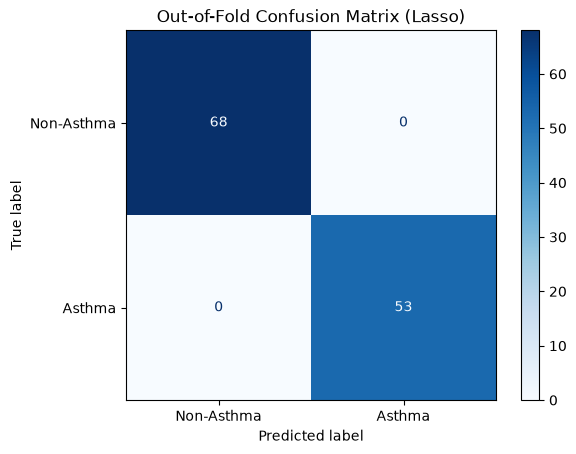

In [22]:
prob_lasso = cross_val_predict(
    estimator=lasso_search,
    X=X,
    y=y,
    cv=lasso_outer_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

y_pred_oof = (prob_lasso >= 0.5).astype(int)

cm = confusion_matrix(y, y_pred_oof)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-Asthma", "Asthma"])
disp.plot(cmap="Blues")
plt.title("Out-of-Fold Confusion Matrix (Lasso)")
plt.show()

Lasso Out-of-Fold Brier Score: 0.0256


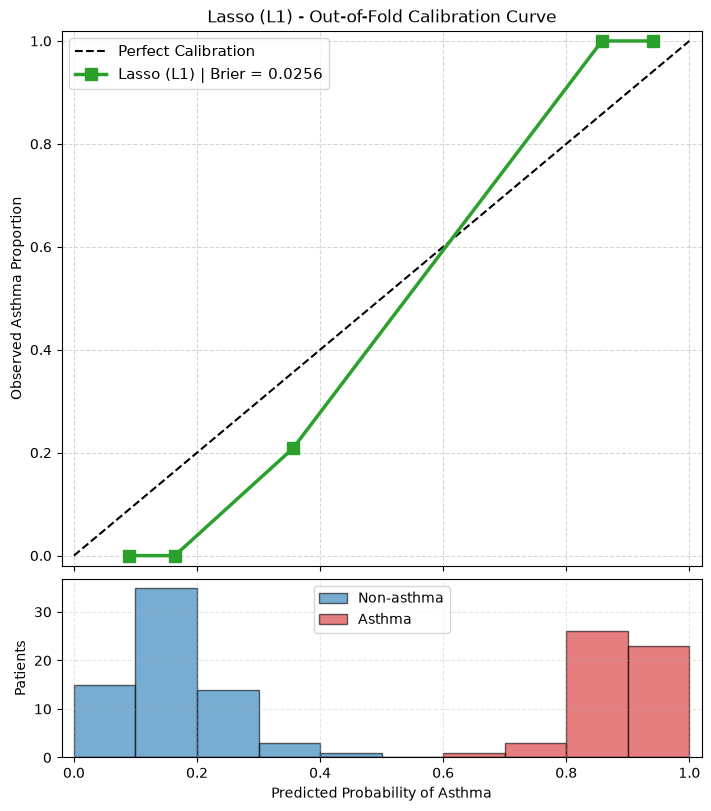

In [23]:
brier = brier_score_loss(y, prob_lasso)
frac_pos, mean_pred = calibration_curve(y, prob_lasso, n_bins=5, strategy="quantile")

print(f"Lasso Out-of-Fold Brier Score: {brier:.4f}")

fig, (ax_cal, ax_hist) = plt.subplots(
    2, 1, 
    figsize=(7, 8), 
    sharex=True, 
    gridspec_kw={"height_ratios": [3, 1]},
    constrained_layout=True
)

ax_cal.plot([0, 1], [0, 1], "k--", lw=1.5, label="Perfect Calibration")
ax_cal.plot(
    mean_pred, 
    frac_pos, 
    "s-", 
    color="#2ca02c", 
    lw=2.5, 
    markersize=8,
    label=f"Lasso (L1) | Brier = {brier:.4f}"
)

ax_cal.set(
    ylabel="Observed Asthma Proportion",
    title="Lasso (L1) - Out-of-Fold Calibration Curve",
    xlim=[-0.02, 1.02],
    ylim=[-0.02, 1.02]
)
ax_cal.legend(loc="upper left", fontsize=11)
ax_cal.grid(True, linestyle="--", alpha=0.5)

hist_bins = np.linspace(0, 1, 11)
ax_hist.hist(
    prob_lasso[y == 0], 
    bins=hist_bins, 
    alpha=0.6, 
    label="Non-asthma", 
    color="#1f77b4", 
    edgecolor="black"
)
ax_hist.hist(
    prob_lasso[y == 1], 
    bins=hist_bins, 
    alpha=0.6, 
    label="Asthma", 
    color="#d62728", 
    edgecolor="black"
)

ax_hist.set(
    xlabel="Predicted Probability of Asthma",
    ylabel="Patients"
)
ax_hist.legend(loc="upper center", fontsize=10)
ax_hist.grid(True, linestyle="--", alpha=0.3)

plt.show()